<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Select the region of interest (ROI) of this dataset and save it as `rois/<dataset>/data.zarr` + `metadata.csv`.
> - **Manuscript panels:** Fig. 1A (dataset collection); input to all downstream analyses
> - **Inputs:** Raw vendor output in `rois/raw/`
> - **Outputs:** `rois/<dataset>/data.zarr`, `metadata.csv`
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# 1. Aim of the notebook

In this notebook we will select specific regions of interest to apply troutpy on, with the aim of characterizing the nature of transcripts outside segmented regions

## Import packages

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys


from troutpy_reproducibility.roi_processing import *

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_te

## Read main path to .zarr file

In [2]:
inpath = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/raw/xenium_opsc_5k"
sdata = spatialdata_io.xenium(inpath)
del sdata['morphology_focus']
output_path = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_opsc_5k"

INFO     reading                                                                                                   
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/raw/xenium_opsc_5k/cell_feature_matrix.h5  


<tifffile.TiffFile 'morphology_focus_0000.ome.tif'> OME series failed to read 'ch0001_atp1a1_cd45_e-cadherin.ome.tif', raised FileNotFoundError(2, 'No such file or directory'). Missing data are zeroed
<tifffile.TiffFile 'morphology_focus_0000.ome.tif'> OME series failed to read 3 files


We decide to keep the data in a unified scale (um), which then can be transformated to 'global' coordinates using the according transformation. This global transformation is specially useful for matching the sales of transcripts with ie images

In [3]:
sdata["table"]

AnnData object with n_obs × n_vars = 200900 × 5001
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

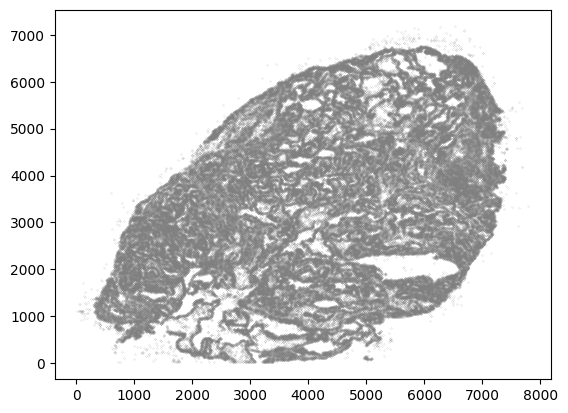

In [4]:
# Visualize using global coordinates
local_coords = sdata["table"].obsm["spatial"]
# In case it's needed, chec transformations
# print(  get_transformation(sdata["nucleus_boundaries"]))
spat = [g[0] for g in sdata["table"].obsm["spatial"]]
spat2 = [g[1] for g in sdata["table"].obsm["spatial"]]
plt.scatter(spat, spat2, s=0.01, c="grey")

In [5]:
# ROI selection
bb_xmin = 10000  # mix x
bb_ymin = 5000  # min y
bb_xmax = 20019  # max x
bb_ymax = 15809.9  # max y

In [6]:
pixel_size_um=4.705

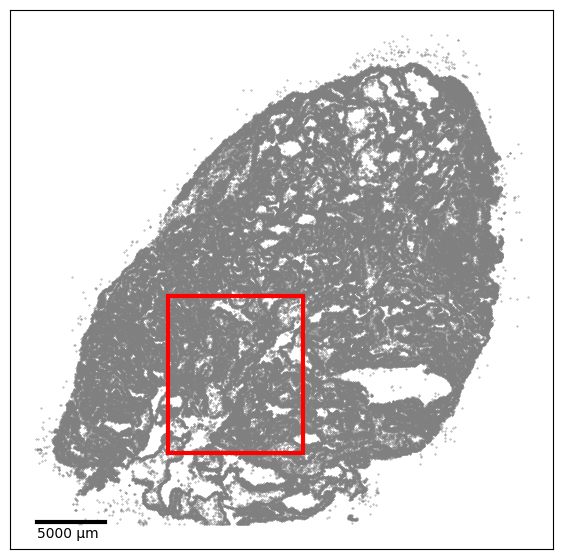

In [7]:
plot_spatial_with_box_and_scale(
    spatial_coords=sdata["table"].obsm["spatial"], bb_xmin=bb_xmin, bb_xmax=bb_xmax, bb_ymin=bb_ymin, bb_ymax=bb_ymax
)

Next, we select the ROI of interest

In [8]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],
    target_coordinate_system="global",
)

In [9]:

# Save metadata
# Save metadata
metadata = generate_metadata(
    sdata=cropped_sdata,
    sample_id="human_opsc",
    species="Hommo Sapiens",
    technology="Xenium",
    segmentation_method="multimodal",
    roi_name="roi_hs_opsc_5k",
    tissue="ovary",
    disease="opsc",
)

rechunk_sdata(cropped_sdata)

Processing label: nucleus_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing label: cell_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...


In [10]:
# troutpy converter to xenium
troutpy.pp.xenium_converter(cropped_sdata, unassigned_tag="UNASSIGNED")

In [11]:
# Define output paths
zarr_path = os.path.join(output_path, "data.zarr")
metadata_path = os.path.join(output_path, "metadata.csv")

cropped_sdata.write(zarr_path, overwrite=True)
metadata.to_csv(metadata_path, index=False)

INFO     The Zarr backing store has been changed from None the new file path:                                      
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_opsc_5k/data.zarr              
